In [2]:
# Kredi Kartı Sahtekârlık Tespiti
# Amaç: Bir kart işleminin sahtekârlık olup olmadığını tahmin etmek.
# Neden önemli: Sahtekârlık çok nadirdir ama her kaçırılan vaka doğrudan para kaybıdır; öte yandan her yanlış alarm bir analistin zamanı ve müşterinin rahatsız edilmesi demektir.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TARGET = "Class"

In [4]:
def load_data(path):
    return pd.read_csv(path)

df = load_data('/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
print("Eksik değer toplamı:", df.isnull().sum().sum())
print("Tekrarlayan satır:", df.duplicated().sum())
print()

print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(5))
print()

print(df[['Time', 'Amount']].describe().round(2))

Eksik değer toplamı: 0
Tekrarlayan satır: 1081

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    0.99827
1    0.00173
Name: proportion, dtype: float64

            Time     Amount
count  284807.00  284807.00
mean    94813.86      88.35
std     47488.15     250.12
min         0.00       0.00
25%     54201.50       5.60
50%     84692.00      22.00
75%    139320.50      77.16
max    172792.00   25691.16


In [6]:
# 1) Tekrarlayan satırlar hangi sınıfta?
tekrar = df.duplicated()
print("Tekrar sayısı (sınıfa göre):")
print(tekrar.groupby(df[TARGET]).sum().to_dict())
print("Tekrarlar silinirse kalan sahtekârlık:", (~tekrar & (df[TARGET] == 1)).sum())
print()

# 2) Aptal modelin accuracy'si
print("Hep 'normal' diyen modelin accuracy'si:", round((df[TARGET] == 0).mean(), 5))
print()

# 3) Zaman: kaç saat, sahtekârlık saate göre nasıl dağılıyor?
df['Hour'] = (df['Time'] // 3600).astype(int)
saat = df.groupby('Hour')[TARGET].agg(['count', 'sum'])
saat['oran_%'] = (saat['sum'] / saat['count'] * 100).round(2)
saat.columns = ['islem', 'sahtekarlik', 'oran_%']
print(saat.T.to_string())
print()

# 4) Zamana göre %80/%20 bölünürse test'te kaç sahtekârlık kalır?
sirali = df.sort_values('Time')
kesim = int(len(sirali) * 0.8)
print("Zaman bölmesi: train sahtekârlık =", sirali.iloc[:kesim][TARGET].sum(),
      "| test sahtekârlık =", sirali.iloc[kesim:][TARGET].sum())
print()

# 5) Tutar sınıfa göre
print(df.groupby(TARGET)['Amount'].describe().round(2))

Tekrar sayısı (sınıfa göre):
{0: 1062, 1: 19}
Tekrarlar silinirse kalan sahtekârlık: 473

Hep 'normal' diyen modelin accuracy'si: 0.99827

Hour              0        1        2        3        4        5        6        7       8        9        10      11       12       13       14       15       16       17       18       19       20       21       22       23       24      25       26       27       28      29       30      31       32       33       34       35      36      37       38       39       40       41       42       43       44       45       46       47
islem        3963.00  2217.00  1576.00  1821.00  1082.00  1681.00  1831.00  3368.00  5179.0  7878.00  8288.00  8517.0  7732.00  7585.00  8029.00  7836.00  7786.00  7882.00  8607.00  7994.00  8980.00  9895.00  8977.00  6082.00  3732.00  2003.0  1752.00  1671.00  1127.00  1309.0  2270.00  3875.0  5097.00  7960.00  8310.00  8339.00  7688.0  7780.0  8541.00  8625.00  8667.00  8284.00  8432.00  7655.00  7776.00  7808.00  6464

In [7]:
### İlk gözlemler
# - 284.807 işlem, 492 sahtekârlık (%0,173); eksik değer yok.
# - Her işleme "normal" diyen model %99,83 accuracy alır; accuracy anlamsız. PR-AUC ve recall/precision kullanacağım.
# - 1.081 tekrarlayan satır var; train/test sızıntısı riski nedeniyle sınıf dağılımı incelenip karar verilecek.
# - Time 0-172.792 sn (~48 saat): veri yalnızca iki günü kapsıyor.
# - Amount çok çarpık (medyan 22, ortalama 88, maksimum 25.691).
# - Test setinde (%20) yaklaşık 98 sahtekârlık kalacağı için tek bir bölmenin sonucu gürültülü; CV kullanılacak.

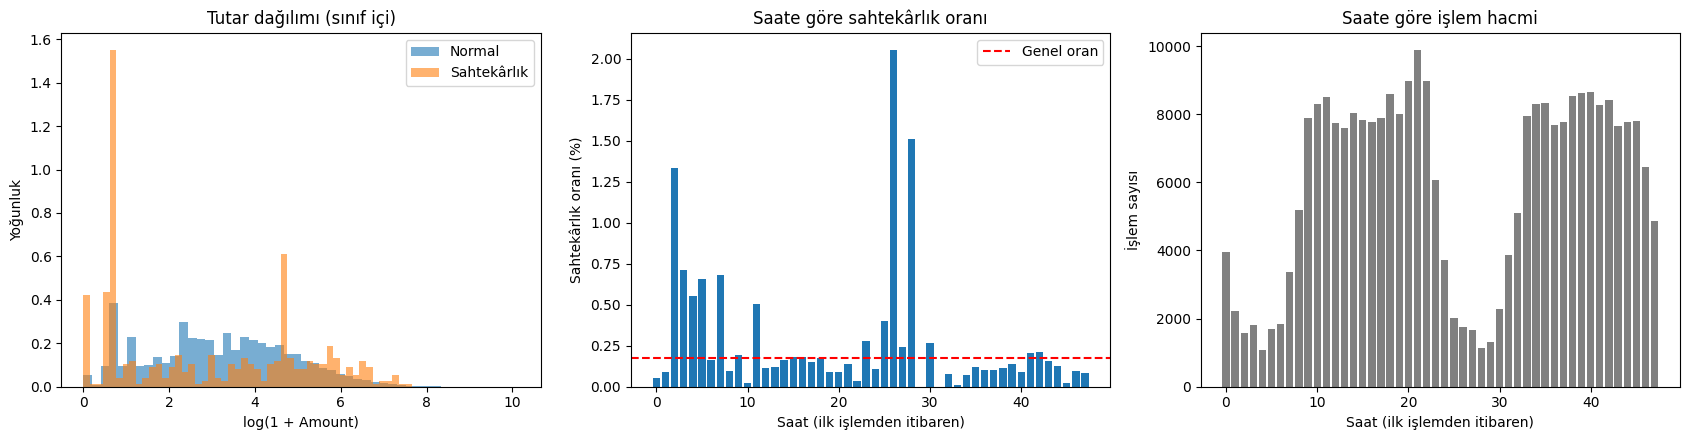

V14    0.949
V4     0.938
V12    0.937
V11    0.918
V10    0.914
V3     0.912
V2     0.855
V16    0.847
V9     0.844
V7     0.836
dtype: float64

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Tutar dağılımı (log ölçek), sınıf içi oran
for sinif, ad in [(0, 'Normal'), (1, 'Sahtekârlık')]:
    axes[0].hist(np.log1p(df.loc[df[TARGET] == sinif, 'Amount']),
                 bins=50, alpha=0.6, density=True, label=ad)
axes[0].set_xlabel('log(1 + Amount)')
axes[0].set_ylabel('Yoğunluk')
axes[0].set_title('Tutar dağılımı (sınıf içi)')
axes[0].legend()

# 2) Saate göre sahtekârlık oranı
oran = df.groupby('Hour')[TARGET].mean() * 100
axes[1].bar(oran.index, oran.values)
axes[1].axhline(df[TARGET].mean() * 100, color='red', linestyle='--', label='Genel oran')
axes[1].set_xlabel('Saat (ilk işlemden itibaren)')
axes[1].set_ylabel('Sahtekârlık oranı (%)')
axes[1].set_title('Saate göre sahtekârlık oranı')
axes[1].legend()

# 3) Saate göre işlem hacmi
hacim = df.groupby('Hour').size()
axes[2].bar(hacim.index, hacim.values, color='gray')
axes[2].set_xlabel('Saat (ilk işlemden itibaren)')
axes[2].set_ylabel('İşlem sayısı')
axes[2].set_title('Saate göre işlem hacmi')

plt.tight_layout()
plt.show()

# Tek özellikli AUC: her özellik tek başına sınıfı ne kadar ayırıyor?
from sklearn.metrics import roc_auc_score
aday = [c for c in df.columns if c.startswith('V')] + ['Amount']
tek_auc = {}
for c in aday:
    a = roc_auc_score(df[TARGET], df[c])
    tek_auc[c] = max(a, 1 - a)   # yön önemli değil, ayırma gücüne bakıyoruz
pd.Series(tek_auc).sort_values(ascending=False).head(10).round(3)

In [9]:
def clean_data(df):
    """Yardımcı sütunu at, tam tekrar eden satırları sil."""
    return df.drop(columns=['Hour'], errors='ignore').drop_duplicates().reset_index(drop=True)

def time_split(df, test_frac=0.2):
    """Zamana göre sırala; son test_frac kadarı test."""
    df = df.sort_values('Time').reset_index(drop=True)
    kesim = int(len(df) * (1 - test_frac))
    return df.iloc[:kesim], df.iloc[kesim:]

df_clean = clean_data(df)
train_df, test_df = time_split(df_clean)

print("Silinen tekrar:", len(df) - len(df_clean))
print("Temiz veri:", df_clean.shape, "| sahtekârlık:", df_clean[TARGET].sum())
for ad, d in [('Train', train_df), ('Test', test_df)]:
    print(f"{ad}: {d.shape[0]} işlem | sahtekârlık: {d[TARGET].sum()} | "
          f"oran: {d[TARGET].mean():.5f} | Time: {int(d['Time'].min())}-{int(d['Time'].max())}")

DROP = [TARGET, 'Time']
X_train, y_train = train_df.drop(columns=DROP), train_df[TARGET]
X_test, y_test = test_df.drop(columns=DROP), test_df[TARGET]
print("Özellik sayısı:", X_train.shape[1])

Silinen tekrar: 1081
Temiz veri: (283726, 31) | sahtekârlık: 473
Train: 226980 işlem | sahtekârlık: 399 | oran: 0.00176 | Time: 0-145233
Test: 56746 işlem | sahtekârlık: 74 | oran: 0.00130 | Time: 145234-172792
Özellik sayısı: 29


In [10]:
### Veri kalitesi ve kararlar
# - 284.807 işlem, 492 sahtekârlık (%0,173); her işleme "normal" diyen model %99,83 accuracy alır, accuracy anlamsız. PR-AUC ve recall/precision kullanılacak (rastgele modelin PR-AUC'si ≈ pozitif oran ≈ 0,0017).
# - 1.081 tam tekrarlayan satır (1.062 normal, 19 sahtekâr) silindi; kalan 473 sahtekârlık. Time dahil tüm sütunlarda birebir aynı olduklarından büyük olasılıkla kayıt tekrarı (çıkarım). Amaç: train/test sızıntısını önlemek.
# - Veri yalnızca ~48 saati kapsıyor. Sahtekârlık oranı gece saatlerinde genelde %1-2 (saat 2: %1,33, saat 26: %2,05, saat 28: %1,51), genel oran %0,17. Sahtekârlık sayısı gece-gündüz benzer, normal işlem hacmi geceleri çok düşük. Ayrıca kümeler halinde patlamalar var (saat 11: 43, saat 26: 36 sahtekârlık). İki günlük veriyle gün içi saat etkisi ile bu patlamalar ayırt edilemediği için Time ve Hour modele girmedi.
# - Sahtekâr işlemlerin tutar medyanı 9,25 (normal: 22), %25'lik dilimi 1,00; ortalama ise daha yüksek (122 vs 88). Küçük tutarlı deneme işlemleri (card testing) olabilir; doğrulanmadı, hipotez.
# - Değerlendirme: zamana göre son %20 test (tek sefer, en sonda); model seçimi train içinde stratified 5-fold CV ile. Test setindeki sahtekârlık sayısı az (~70-75), tek test sonucu gürültülü.

In [11]:
### Grafik ve bölme gözlemleri
# - Sahtekâr işlemlerin tutarı üç noktada yığılıyor: ~0, ~1 ve ~100 (log1p ölçeğinde ~0, ~0,7, ~4,6). Küçük tutarlar kart deneme (card testing), ~100 yuvarlak tutar olabilir; doğrulanmadı, hipotez.
# - Sahtekârlık oranı, işlem hacminin düşük olduğu saatlerde yüksek; Time ve Hour yine modele girmedi.
# - Tek özellikli AUC: V14 0,949, V4 0,938, V12 0,937, V11 0,918, V10 0,914, V3 0,912 (tüm veri üzerinde, yalnızca keşif amaçlı). Tek özellik bile ROC-AUC ~0,95 verdiği için ROC-AUC modelleri ayırmakta zayıf kalacak; PR-AUC birincil metrik.
# - Zaman bölmesi: Train 226.980 işlem / 399 sahtekârlık (%0,176), Test 56.746 işlem / 74 sahtekârlık (%0,130). Test, verinin son ~7,7 saatini kapsıyor; sahtekârlık oranı train'den düşük. Test sonucu bu dar pencere için bir ölçüm, tek vaka recall'u ~1,35 puan oynatır.
# - Rastgele modelin PR-AUC'si: train'de ~0,0018, testte ~0,0013.

In [12]:
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from lightgbm import LGBMClassifier

def top_k_capture(y_true, score, q=0.005):
    y_true = np.asarray(y_true)
    n = max(1, int(len(y_true) * q))
    idx = np.argsort(-np.asarray(score))[:n]
    return y_true[idx].sum() / y_true.sum()

def score_model(model, X_te, y_te):
    p = model.predict_proba(X_te)[:, 1]
    return {
        'PR-AUC': average_precision_score(y_te, p),
        'ROC-AUC': roc_auc_score(y_te, p),
        'Top %0,5 yakalama': top_k_capture(y_te, p),
    }

def make_logreg(**kw):
    pre = ColumnTransformer(
        [('amt', FunctionTransformer(np.log1p, feature_names_out='one-to-one'), ['Amount'])],
        remainder='passthrough'
    )
    return Pipeline([
        ('pre', pre),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **kw)),
    ])

def make_lgbm(**kw):
    return LGBMClassifier(
        n_estimators=300, learning_rate=0.03, num_leaves=15,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=RANDOM_STATE, verbose=-1, **kw
    )

def build_models(y_tr):
    spw = float(np.sqrt((y_tr == 0).sum() / (y_tr == 1).sum()))   # tam oranın karekökü (ara değer)
    return {
        'Lojistik Regresyon': make_logreg(),
        'Lojistik Reg. (balanced)': make_logreg(class_weight='balanced'),
        'LightGBM': make_lgbm(),
        'LightGBM (scale_pos_weight=√oran)': make_lgbm(scale_pos_weight=spw),
    }

def run_cv(splitter, X, y, sema):
    rows = []
    for fold, (tr, va) in enumerate(splitter.split(X, y), 1):
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr], y.iloc[va]
        for ad, m in build_models(y_tr).items():
            s = score_model(m.fit(X_tr, y_tr), X_va, y_va)
            s.update({'Model': ad, 'Fold': fold, 'Şema': sema,
                      'Val sahtekarlik': int(y_va.sum())})
            rows.append(s)
    return pd.DataFrame(rows)

cv_strat = run_cv(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                  X_train, y_train, 'Stratified 5-fold')
cv_time = run_cv(TimeSeriesSplit(n_splits=4), X_train, y_train, 'Zaman bazlı')
cv_all = pd.concat([cv_strat, cv_time])

metrikler = ['PR-AUC', 'ROC-AUC', 'Top %0,5 yakalama']
display(cv_all.groupby(['Şema', 'Model'])[metrikler].agg(['mean', 'std']).round(3))

print("Zaman bazlı CV, doğrulama dilimlerindeki sahtekârlık sayıları:",
      cv_time.groupby('Fold')['Val sahtekarlik'].first().to_dict())
display(cv_time.pivot(index='Fold', columns='Model', values='PR-AUC').round(3))

PR-AUC        ROC-AUC  \
                                                      mean    std    mean   
Şema              Model                                                     
Stratified 5-fold LightGBM                           0.829  0.031   0.977   
                  LightGBM (scale_pos_weight=√oran)  0.367  0.258   0.859   
                  Lojistik Reg. (balanced)           0.718  0.015   0.970   
                  Lojistik Regresyon                 0.742  0.021   0.971   
Zaman bazlı       LightGBM                           0.758  0.041   0.963   
                  LightGBM (scale_pos_weight=√oran)  0.542  0.323   0.899   
                  Lojistik Reg. (balanced)           0.651  0.149   0.939   
                  Lojistik Regresyon                 0.526  0.192   0.940   

                                                           Top %0,5 yakalama  \
                                                       std              mean   
Şema              Model                                                        
Stratified 5-fold LightGBM                           0.006             0.875   
                  LightGBM (scale_pos_weight=√oran)  0.042             0.692   
                  Lojistik Reg. (balanced)           0.006             0.855   
                  Lojistik Regresyon                 0.010             0.857   
Zaman bazlı       LightGBM                           0.028             0.814   
                  LightGBM (scale_pos_weight=√oran)  0.060             0.693   
                  Lojistik Reg. (balanced)           0.039             0.785   
                  Lojistik Regresyon                 0.027             0.714   

                                                            
                                                       std  
Şema              Model                                     
Stratified 5-fold LightGBM                           0.032  
                  LightGBM (scale_pos_weight=√oran)  0.110  
                  Lojistik Reg. (balanced)           0.024  
                  Lojistik Regresyon                 0.021  
Zaman bazlı       LightGBM                           0.054  
                  LightGBM (scale_pos_weight=√oran)  0.170  
                  Lojistik Reg. (balanced)           0.051  
                  Lojistik Regresyon                 0.088

Zaman bazlı CV, doğrulama dilimlerindeki sahtekârlık sayıları: {1: 69, 2: 47, 3: 89, 4: 52}


Model,LightGBM,LightGBM (scale_pos_weight=√oran),Lojistik Reg. (balanced),Lojistik Regresyon
Fold,,,,
1,0.796,0.796,0.528,0.290
2,0.704,0.668,0.522,0.449
3,0.783,0.634,0.814,0.703
4,0.748,0.068,0.741,0.660


In [13]:
# 0) scale_pos_weight'li LightGBM: stratified fold'larda ne oluyor?
display(cv_strat.pivot(index='Fold', columns='Model', values='PR-AUC').round(3))

# 1) SMOTE ve Isolation Forest
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import IsolationForest

def make_smote_model(base):
    pre = ColumnTransformer(
        [('amt', FunctionTransformer(np.log1p, feature_names_out='one-to-one'), ['Amount'])],
        remainder='passthrough')
    return ImbPipeline([
        ('pre', pre),
        ('scaler', StandardScaler()),   # SMOTE mesafe kullanır; Amount ölçeklenmeli
        ('smote', SMOTE(sampling_strategy=0.1, k_neighbors=5, random_state=RANDOM_STATE)),
        ('model', base),
    ])

class IsoScorer:
    """Isolation Forest: etiket kullanmaz, anomali skoru üretir (yüksek = daha anormal)."""
    def __init__(self, **kw):
        self.m = IsolationForest(**kw)
    def fit(self, X, y=None):
        self.m.fit(X)
        return self
    def predict_proba(self, X):
        s = -self.m.score_samples(X)
        return np.column_stack([-s, s])

def build_models_v2(y_tr):
    return {
        'Lojistik Reg. + SMOTE': make_smote_model(
            LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        'LightGBM + SMOTE': make_smote_model(make_lgbm()),
        'Isolation Forest (denetimsiz)': IsoScorer(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    }

def run_cv_with(builder, splitter, X, y, sema):
    rows = []
    for fold, (tr, va) in enumerate(splitter.split(X, y), 1):
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr], y.iloc[va]
        for ad, m in builder(y_tr).items():
            s = score_model(m.fit(X_tr, y_tr), X_va, y_va)
            s.update({'Model': ad, 'Fold': fold, 'Şema': sema,
                      'Val sahtekarlik': int(y_va.sum())})
            rows.append(s)
    return pd.DataFrame(rows)

cv_new = pd.concat([
    run_cv_with(build_models_v2, StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                X_train, y_train, 'Stratified 5-fold'),
    run_cv_with(build_models_v2, TimeSeriesSplit(n_splits=4),
                X_train, y_train, 'Zaman bazlı'),
])

tum = pd.concat([cv_all, cv_new])
tum = tum[tum['Model'] != 'LightGBM (scale_pos_weight=√oran)']
metrikler = ['PR-AUC', 'ROC-AUC', 'Top %0,5 yakalama']
display(tum.groupby(['Şema', 'Model'])[metrikler].agg(['mean', 'std']).round(3))

Model,LightGBM,LightGBM (scale_pos_weight=√oran),Lojistik Reg. (balanced),Lojistik Regresyon
Fold,,,,
1,0.876,0.608,0.708,0.742
2,0.834,0.677,0.715,0.766
3,0.819,0.126,0.704,0.710
4,0.823,0.162,0.725,0.754
5,0.791,0.263,0.740,0.735


PR-AUC        ROC-AUC         \
                                                  mean    std    mean    std   
Şema              Model                                                        
Stratified 5-fold Isolation Forest (denetimsiz)  0.191  0.042   0.946  0.019   
                  LightGBM                       0.829  0.031   0.977  0.006   
                  LightGBM + SMOTE               0.856  0.020   0.977  0.007   
                  Lojistik Reg. (balanced)       0.718  0.015   0.970  0.006   
                  Lojistik Reg. + SMOTE          0.744  0.013   0.969  0.010   
                  Lojistik Regresyon             0.742  0.021   0.971  0.010   
Zaman bazlı       Isolation Forest (denetimsiz)  0.095  0.113   0.930  0.036   
                  LightGBM                       0.758  0.041   0.963  0.028   
                  LightGBM + SMOTE               0.755  0.052   0.958  0.029   
                  Lojistik Reg. (balanced)       0.651  0.149   0.939  0.039   
                  Lojistik Reg. + SMOTE          0.721  0.083   0.944  0.031   
                  Lojistik Regresyon             0.526  0.192   0.940  0.027   

                                                Top %0,5 yakalama         
                                                             mean    std  
Şema              Model                                                   
Stratified 5-fold Isolation Forest (denetimsiz)             0.448  0.060  
                  LightGBM                                  0.875  0.032  
                  LightGBM + SMOTE                          0.875  0.015  
                  Lojistik Reg. (balanced)                  0.855  0.024  
                  Lojistik Reg. + SMOTE                     0.857  0.026  
                  Lojistik Regresyon                        0.857  0.021  
Zaman bazlı       Isolation Forest (denetimsiz)             0.272  0.182  
                  LightGBM                                  0.814  0.054  
                  LightGBM + SMOTE                          0.811  0.055  
                  Lojistik Reg. (balanced)                  0.785  0.051  
                  Lojistik Reg. + SMOTE                     0.801  0.055  
                  Lojistik Regresyon                        0.714  0.088

In [14]:
### Baseline modeller: iki doğrulama şeması (train içinde)
# - ROC-AUC, scale_pos_weight'li LightGBM hariç tüm modellerde yüksek (0,94-0,98); modelleri PR-AUC ayırıyor, birincil metrik PR-AUC.
# - Stratified 5-fold PR-AUC: LightGBM 0,829 ± 0,031, lojistik 0,742 ± 0,021, balanced lojistik 0,718 ± 0,015.
# - Zaman bazlı CV (4 fold, doğrulama dilimlerinde 47-89 sahtekârlık): LightGBM 0,758 ± 0,041, balanced lojistik 0,651 ± 0,149, lojistik 0,526 ± 0,192. Tüm modellerde zaman bazlı skor daha düşük; bunun bir kısmı gelecekteki dağılım kayması olabilir, bir kısmı ise zaman bazlı CV'nin ilk fold'larının daha az eğitim verisi (fold 1: verinin ~%20'si) kullanması.
# - LightGBM zaman bazlı fold'ların dördünde ikisini değil üçünü kazandı (fold 3'te balanced lojistik önde: 0,814 vs 0,783).
# - Normal ve balanced lojistik regresyon arasındaki sıralama şemaya göre değişiyor (stratified: normal önde, fark ~1 std; zaman bazlı: balanced 4/4 fold'da önde). Sınıf ağırlığının etkisi hakkında net bir sonuca varılamadı.
# - LightGBM'in en riskli %0,5'lik işlem dilimi sahtekârlıkların %87,5'ini (stratified) / %81,4'ünü (zaman bazlı) yakalıyor.
# - scale_pos_weight=√oran (~24) kullanan LightGBM kararsız (PR-AUC 0,367 ± 0,258, zaman bazlı son fold'da 0,068). Nedeni araştırılmadı; hipotez: az sayıdaki pozitif örneğin ezberlenmesi.

In [15]:
# - LightGBM zaman bazlı fold'ların dördünün üçünde en yüksek PR-AUC'yi verdi (fold 3'te balanced lojistik regresyon önde: 0,814 vs 0,783).
# - scale_pos_weight=√oran kullanan LightGBM, rastgele (stratified) fold'larda da kararsız (PR-AUC fold bazında 0,608 / 0,677 / 0,126 / 0,162 / 0,263); sorun zamana bağlı değil, nedeni araştırılmadı. Final adaylardan çıkarıldı.

### SMOTE ve Isolation Forest
# - SMOTE (yalnızca her fold'un eğitim kısmında, sampling_strategy=0,1): LightGBM'de stratified PR-AUC 0,829 → 0,856, zaman bazlı 0,758 → 0,755 (fark std içinde). Lojistik regresyonda zaman bazlı 0,526 → 0,721 (std'ler 0,192 ve 0,083, fark kesin değil). SMOTE final modele eklenmedi.
# - Isolation Forest (etiket kullanmıyor): PR-AUC 0,191 ± 0,042 (stratified) ve 0,095 ± 0,113 (zaman bazlı); rastgele model ~0,002. Sahtekârlıkların bir kısmı etiketsiz de ayrışıyor ama denetimli modelin belirgin altında; ROC-AUC 0,93-0,95 olmasına rağmen PR-AUC düşük.
# - Final model: SMOTE'suz LightGBM (varsayılana yakın ayarlar, hiperparametre ayarı yapılmadı).

In [17]:
final = make_lgbm().fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
y_arr = y_test.to_numpy()

def metrikler_hesapla(y_true, p): return {'PR-AUC': average_precision_score(y_true, p), 'ROC-AUC': roc_auc_score(y_true, p), 'Top %0,5 yakalama': top_k_capture(y_true, p)}

nokta = metrikler_hesapla(y_arr, p_test)

rng = np.random.default_rng(RANDOM_STATE)
idx_list = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(500)]
idx_list = [i for i in idx_list if y_arr[i].sum() > 0]
boot = pd.DataFrame([metrikler_hesapla(y_arr[i], p_test[i]) for i in idx_list])

print("Test:", len(y_arr), "işlem |", int(y_arr.sum()), "sahtekârlık | rastgele model PR-AUC ≈", round(y_arr.mean(), 4))
pd.DataFrame({'Nokta tahmin': pd.Series(nokta),
              '%2,5': boot.quantile(0.025),
              '%97,5': boot.quantile(0.975)}).round(3)

Test: 56746 işlem | 74 sahtekârlık | rastgele model PR-AUC ≈ 0.0013


,Nokta tahmin,"%2,5","%97,5"
PR-AUC,0.733,0.622,0.843
ROC-AUC,0.982,0.965,0.995
"Top %0,5 yakalama",0.851,0.761,0.928


In [18]:
amount_test = X_test['Amount'].to_numpy()
sira = np.argsort(-p_test)
toplam_sahtekarlik = y_arr.sum()
toplam_tutar = amount_test[y_arr == 1].sum()

def kapasite_satiri(q): n = int(len(y_arr) * q); sec = sira[:n]; tp = y_arr[sec].sum(); return {'İncelenen oran (%)': round(q * 100, 2), 'İncelenen işlem': n, 'Yakalanan sahtekârlık': int(tp), 'Precision': round(tp / n, 3), 'Recall': round(tp / toplam_sahtekarlik, 3), 'Yakalanan tutar oranı': round(amount_test[sec][y_arr[sec] == 1].sum() / toplam_tutar, 3)}

pd.DataFrame([kapasite_satiri(q) for q in [0.001, 0.0025, 0.005, 0.01, 0.02]])

,İncelenen oran (%),İncelenen işlem,Yakalanan sahtekârlık,Precision,Recall,Yakalanan tutar oranı
0,0.10,56,50,0.893,0.676,0.627
1,0.25,141,60,0.426,0.811,0.737
2,0.50,283,63,0.223,0.851,0.739
3,1.00,567,65,0.115,0.878,0.822
4,2.00,1134,66,0.058,0.892,0.824


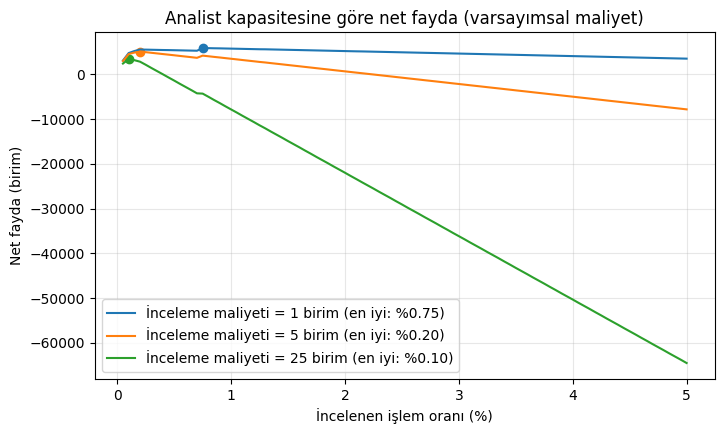

Test setindeki sahtekârlıkların toplam tutarı: 7728.0


In [19]:
def net_fayda_tek(q, c): n = int(len(y_arr) * q); sec = sira[:n]; return amount_test[sec][y_arr[sec] == 1].sum() - c * n

qs = np.linspace(0.0005, 0.05, 100)
plt.figure(figsize=(8, 4.5))
for c in [1, 5, 25]: f = np.array([net_fayda_tek(q, c) for q in qs]); i = f.argmax(); plt.plot(qs * 100, f, label=f'İnceleme maliyeti = {c} birim (en iyi: %{qs[i] * 100:.2f})'); plt.scatter(qs[i] * 100, f[i])
plt.xlabel('İncelenen işlem oranı (%)')
plt.ylabel('Net fayda (birim)')
plt.title('Analist kapasitesine göre net fayda (varsayımsal maliyet)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("Test setindeki sahtekârlıkların toplam tutarı:", round(toplam_tutar, 0))

In [20]:
### Final model: zaman bazlı test (tek sefer)
# - Final model: SMOTE'suz LightGBM. Test: zamana göre son %20 (56.746 işlem, 74 sahtekârlık, test oranı %0,130; rastgele model PR-AUC ≈ 0,0013). Test setine yalnızca bir kez bakıldı.
# - PR-AUC 0,733 (%95 bootstrap aralığı 0,622-0,843), ROC-AUC 0,982 (0,965-0,995), Top %0,5 yakalama %85,1 (%76,1-%92,8). Sonuçlar zaman bazlı CV ile uyumlu (PR-AUC 0,758 ± 0,041).
# - Aralıklar geniş çünkü yalnızca 74 sahtekârlık var; bootstrap işlemleri bağımsız örneklediği için sahtekârlık kümelenmesini hesaba katmıyor, gerçek belirsizlik muhtemelen daha büyük.
# - Test seti verinin son ~7,7 saatini kapsıyor ve sahtekârlık oranı train'den düşük; sonuçlar bu pencere için bir ölçüm.

In [21]:
### Analist kapasitesi ve net fayda (test seti, varsayımsal maliyet)
# - İşlemlerin %0,10'unu (56 işlem) incelemek 74 sahtekârlığın 50'sini yakalıyor (precision %89,3, recall %67,6); %0,5'te (283 işlem) 63'ünü (precision %22,3, recall %85,1); %2'de (1.134 işlem) 66'sını (precision %5,8, recall %89,2). Getiri hızla azalıyor.
# - Yakalanan tutar oranı recall'dan düşük (%0,5'te %73,9 vs %85,1): kaçırılan sahtekârlıklar ortalamada daha büyük tutarlı.
# - Net fayda = yakalanan sahtekârlık tutarı − inceleme maliyeti × incelenen işlem. Maliyet 1 / 5 / 25 birim iken en iyi inceleme oranı %0,75 / %0,20 / %0,10. Optimum, "inceleme maliyeti ÷ ortalama yakalanan tutar" (~91-95 birim) kadar bir dilim precision'ına denk gelen noktaya yakın (kendi yaklaşık hesabım).
# - Sınırlılıklar: toplam sahtekârlık tutarı 7.728 birim, 74 sahtekârlık, tek 7,7 saatlik pencere; optimum noktaları kesin değil. Para birimi belirtilmediği için "birim" kullanıldı. Chargeback, müşteri rahatsızlığı gibi maliyetler hesaba katılmadı.

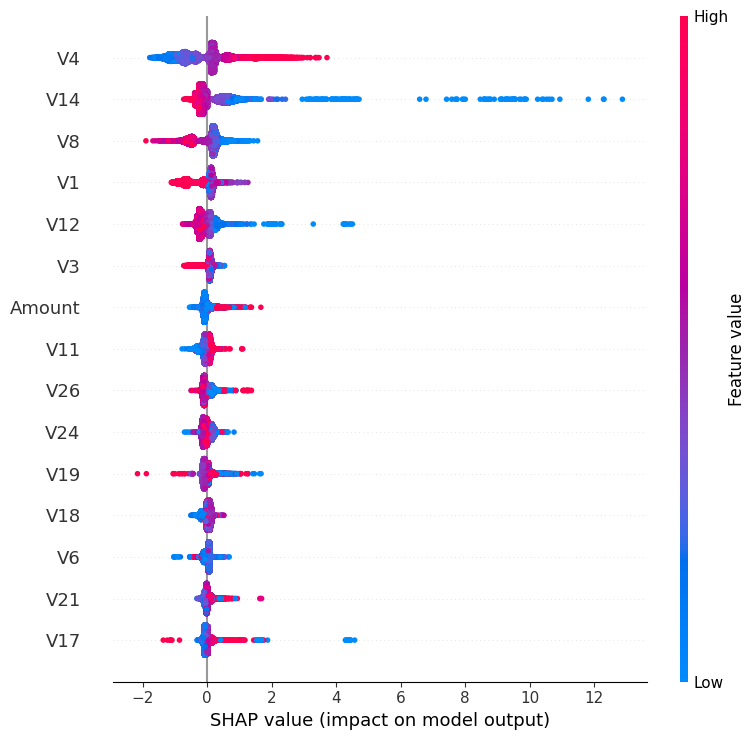

,Tüm işlemler,Sadece sahtekârlıklar
V14,0.335,6.766
V10,0.058,2.601
V4,0.621,1.949
V12,0.179,1.516
V17,0.065,1.221
V8,0.324,0.944
V22,0.054,0.507
V28,0.053,0.404
V15,0.053,0.326
V3,0.119,0.312


In [24]:
import shap

explainer = shap.TreeExplainer(final)
sv = explainer(X_test.astype(float))
vals = sv.values if sv.values.ndim == 2 else sv.values[:, :, 1]

shap.summary_plot(vals, X_test.astype(float), max_display=15, show=True)

onem_tum = pd.Series(np.abs(vals).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
onem_sahte = pd.Series(np.abs(vals[y_arr == 1]).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
pd.DataFrame({'Tüm işlemler (ort. |SHAP|)': onem_tum.head(10).round(3), 'Sadece sahtekârlıklar': onem_sahte.head(10).round(3)})

tablo = pd.DataFrame({'Tüm işlemler': onem_tum, 'Sadece sahtekârlıklar': onem_sahte})
tablo.sort_values('Sadece sahtekârlıklar', ascending=False).head(10).round(3)

In [25]:
### Açıklanabilirlik (SHAP, test seti, final LightGBM)
# - Özellikler anonim PCA bileşenleri (V1-V28); hangi bileşenin önemli olduğu söylenebilir, ne anlama geldiği söylenemez.
# - Tüm işlemlerde ortalama |SHAP|: V4 0,621, V14 0,335, V8 0,324, V1 0,299, V12 0,179. Yalnızca sahtekârlıklarda (74 işlem): V14 6,766, V10 2,601, V4 1,949, V12 1,516, V17 1,221. Sahtekârlıkları ayıran özellikler genel ortalamadan farklı; V10 genel ortalamada ilk 15'te yok.
# - Beeswarm'a göre V14 ve V12 düşükken, V4 yüksekken risk skoru artıyor (V14 için SHAP değerleri 12-13'e ulaşıyor).
# - Amount genel listede 7. (0,107), sahtekârlıklarda ilk 10'da değil.
# - SHAP değerleri log-odds ölçeğinde; sahtekârlık ortalamaları 74 işleme dayanıyor.

In [26]:
## Sonuç ve Sınırlılıklar

# **Sonuç**
# - 284.807 işlem, 492 sahtekârlık (%0,173). 1.081 tam tekrar satır (19'u sahtekâr) silindi; 283.726 işlem, 473 sahtekârlık kaldı. Time ve Hour modele girmedi.
# - Zamana göre bölme: train 226.980 işlem / 399 sahtekârlık, test 56.746 işlem / 74 sahtekârlık (verinin son ~7,7 saati).
# - ROC-AUC modelleri ayırmadı (tek özellik bile ~0,95); birincil metrik PR-AUC. Zaman bazlı CV'de LightGBM PR-AUC 0,758 ± 0,041, balanced lojistik 0,651 ± 0,149, lojistik 0,526 ± 0,192. Stratified CV daha iyimser (LightGBM 0,829 ± 0,031).
# - SMOTE LightGBM'e zaman bazlı CV'de kazanç sağlamadı (0,758 → 0,755); scale_pos_weight=√oran kararsız çıktı; Isolation Forest (etiketsiz) PR-AUC 0,191 / 0,095 ile denetimli modelin belirgin altında.
# - Final model (SMOTE'suz LightGBM) test setinde: PR-AUC 0,733 (%95 aralık 0,622-0,843), ROC-AUC 0,982, Top %0,5 yakalama %85,1 (%76,1-%92,8).
# - Analist kapasitesi: işlemlerin %0,10'unu incelemek 74 sahtekârlığın 50'sini yakalıyor (precision %89,3); %0,5'i 63'ünü (precision %22,3); %2'si 66'sını.

# Sınırlılıklar
# - Yalnızca ~48 saatlik tek bir pencere; test seti 74 sahtekârlık içeriyor. Sonuçlar bu pencere için bir ölçümdür ve belirsizlik geniştir. Bootstrap aralığı işlemleri bağımsız örnekliyor, sahtekârlık kümelenmesini hesaba katmıyor.
# - Tekrar satırların kayıt tekrarı olduğu çıkarımdır, doğrulanmadı.
# - Özellikler anonim PCA bileşenleri: açıklanabilirlik sınırlı, özellik mühendisliği yapılamadı.
# - Time/Hour dışarıda bırakıldı; gün içi saat etkisi ile iki sahtekârlık patlamasını ayırmak mümkün değil. Tutar yığılmaları (~0, ~1, ~100) için card testing yorumu hipotezdir.
# - LightGBM için hiperparametre ayarı yapılmadı; scale_pos_weight'in neden kararsız olduğu araştırılmadı; normal ve balanced lojistik arasındaki sıralama şemaya göre değişti.
# - Net fayda hesabı varsayımsal ve yalnızca yakalanan tutarı sayıyor; para birimi bilinmiyor, chargeback ve müşteri rahatsızlığı maliyetleri yok. Optimum inceleme oranları kesin değil.
# - Yakalanan tutar oranı recall'dan düşük (%0,5'te %73,9 vs %85,1): kaçırılan sahtekârlıklar ortalamada daha büyük; tutara göre ağırlıklandırma denenmedi.